In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
root = "heldout_results"

lstm = pd.read_csv(f"{root}/lstm_h128_wd01/heldout_predictions.csv")
pool = pd.read_csv(f"{root}/pool_fasttext300/heldout_predictions.csv")

paired = lstm.merge(
    pool,
    on=["item_id", "run", "fold"],
    suffixes=("_lstm", "_pool"),
    validate="one_to_one"
)

assert len(paired) == 872 * 5
assert (paired["sentence_lstm"] == paired["sentence_pool"]).all()
assert (paired["label_lstm"] == paired["label_pool"]).all()

# One row per sentence, averaged over five checkpoints
items = paired.groupby("item_id", as_index=False).agg(
    sentence=("sentence_lstm", "first"),
    label=("label_lstm", "first"),
    length=("lexicon_count_lstm", "first"),
    lstm_acc=("correct_lstm", "mean"),
    pool_acc=("correct_pool", "mean"),
    lstm_votes=("pred_lstm", "sum"),
    pool_votes=("pred_pool", "sum")
)

items["advantage"] = items["lstm_acc"] - items["pool_acc"]

print(f"Sentences: {len(items)}")
print(f"LSTM accuracy: {items['lstm_acc'].mean():.2%}")
print(f"Pooling accuracy: {items['pool_acc'].mean():.2%}")
print(f"Advantage: {items['advantage'].mean()*100:+.2f} pp")


Sentences: 872
LSTM accuracy: 86.19%
Pooling accuracy: 80.73%
Advantage: +5.46 pp


,n,lstm,pool,advantage_pp
length_bin,,,,
1–5,57,0.926,0.916,1.053
6–10,142,0.880,0.846,3.380
11–15,192,0.873,0.815,5.833
16–20,187,0.866,0.791,7.487
>20,294,0.831,0.773,5.782


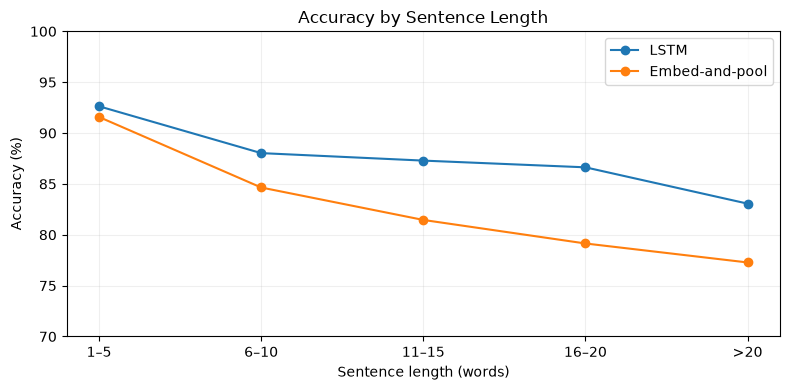

In [8]:

items["length_bin"] = pd.cut(
    items["length"],
    bins=[0, 5, 10, 15, 20, np.inf],
    labels=["1–5", "6–10", "11–15", "16–20", ">20"]
)

length_results = items.groupby(
    "length_bin", observed=True
).agg(
    n=("item_id", "size"),
    lstm=("lstm_acc", "mean"),
    pool=("pool_acc", "mean")
)

length_results["advantage_pp"] = (
    length_results["lstm"] - length_results["pool"]
) * 100

display(length_results.round(3))

plt.figure(figsize=(8, 4))
plt.plot(
    length_results.index.astype(str),
    length_results["lstm"] * 100,
    marker="o", label="LSTM"
)
plt.plot(
    length_results.index.astype(str),
    length_results["pool"] * 100,
    marker="o", label="Embed-and-pool"
)
plt.xlabel("Sentence length (words)")
plt.ylabel("Accuracy (%)")
plt.title("Accuracy by Sentence Length")
plt.ylim(70, 100)
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


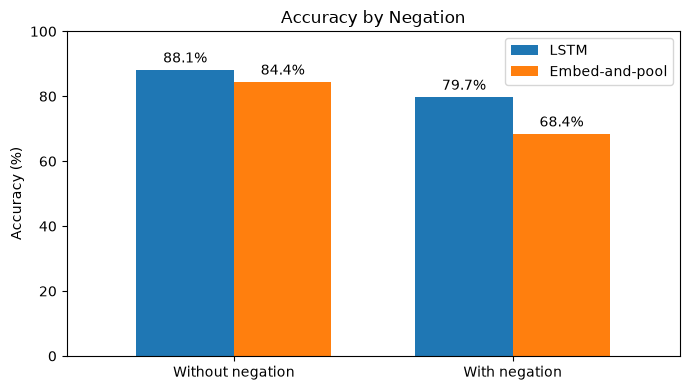

In [12]:
groups = {
    "Without negation": items[~items["negation"]],
    "With negation": items[items["negation"]]
}

results = pd.DataFrame({
    "LSTM": [g["lstm_acc"].mean() * 100 for g in groups.values()],
    "Embed-and-pool": [g["pool_acc"].mean() * 100 for g in groups.values()]
}, index=groups.keys())

ax = results.plot(kind="bar", figsize=(7, 4), width=0.7)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

ax.set_title("Accuracy by Negation")
ax.set_xlabel("")
ax.set_ylabel("Accuracy (%)")
ax.set_xticklabels(results.index, rotation=0)
ax.set_ylim(0, 100)
ax.legend()
plt.tight_layout()
plt.show()